In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.multiclass import OneVsRestClassifier
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC_patient_split,
    find_all_indices,
    get_freqs,
    hot_coding,
)
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient, color_palette_full

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

# set prints off
mask.prints = False

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

Healthy vs. cancer

Healthy: 89 entries
Cancer: 91 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(180, 31, 7728) (180, 2) (180,)


## Analysis stage: Frequency selection **and** IIVV selection

In [6]:
# load masking selection
Mask_sel = {
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Close skip 1": "vv_distance_close_skip_1",
    "All": "all",
}

In [6]:
# load frequency selection results from `frequency-analysis.ipynb`
tmp = np.load("results/freq_fold_results.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

Freq_sel = {
    "Top 2": top_2,
    "Top 3": top_3,
    "Top 5": top_5,
    "Top 12": top_12,
    "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

In [8]:
Freq_sel

{'Top 2': array([30,  0]),
 'Top 3': array([30,  0, 27]),
 'Top 5': array([30,  0, 27, 12, 29]),
 'Top 12': array([30,  0, 27, 12, 29, 28, 13, 16, 20,  8, 26, 23]),
 'All': array([30,  0, 27, 12, 29, 28, 13, 16, 20,  8, 26, 23, 11, 24, 25, 15, 10,
        17, 22,  1, 21, 19, 14,  2,  7, 18,  3,  4,  5,  9,  6])}

In [9]:
Mask_sel

{'Long a+': 'vv_long_across',
 'Long a+ ext.': 'vv_long_across_extended',
 'Med. a+ ext.': 'vv_medium_across_extended',
 'Close skip 1': 'vv_distance_close_skip_1',
 'All': 'all'}

In [ ]:
# setup folds
n_folds = 5
random_state = 0


unique_patients = np.unique(Case)
np.random.seed(random_state)

# Check if Y is in one-hot encoding
if len(Y.shape) == 1 or Y.shape[1] == 1:
    raise ValueError("Labels (Y) must be in one-hot encoding format")
n_classes = Y.shape[1]

patient_indices = np.arange(len(unique_patients))
np.random.shuffle(patient_indices)

# Split these indices into n_folds
fold_size = len(patient_indices) // n_folds
folds = []

for i in range(n_folds):
    if i == n_folds - 1:
        # Last fold gets all remaining patients
        test_indices = patient_indices[i * fold_size :]
    else:
        test_indices = patient_indices[i * fold_size : (i + 1) * fold_size]
    # Training indices are all other indices
    train_indices = np.setdiff1d(patient_indices, test_indices)
    folds.append((train_indices, test_indices))

In [11]:
def foldstats(train_mask, test_mask):
    # Verify split
    train_pct = train_mask.mean() * 100
    test_pct = test_mask.mean() * 100
    print(f"\nFold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")

    # Count samples and patients in each set
    train_samples = np.sum(train_mask)
    test_samples = np.sum(test_mask)
    train_patient_count = len(train_patients)
    test_patient_count = len(test_patients)

    print(f"Fold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")
    print(f"  Training: {train_samples} samples from {train_patient_count} patients")
    print(f"  Testing:  {test_samples} samples from {test_patient_count} patients")


def ROC_AUC_for_class(Y_test, y_score, n_classes):
    # Compute ROC AUC for each class
    roc_auc_scores = []
    for i in range(n_classes):
        score = roc_auc_score(Y_test[:, i], y_score[:, i])
        roc_auc_scores.append(score)
    # Calculate average AUC across classes
    avg_auc = np.mean(roc_auc_scores) if roc_auc_scores else 0
    return avg_auc


def ConfusionMatrix_Stats(y_pred, Y_test, inverse_mapping):

    y_test_tuples = [tuple(row) for row in Y_test.astype(int)]
    y_pred_tuples = [tuple(row) for row in y_pred.astype(int)]
    # inverse mapping
    y_test_labels = [inverse_mapping[t] for t in y_test_tuples]
    y_pred_labels = [inverse_mapping[t] for t in y_pred_tuples]
    class_labels = list(inverse_mapping.values())
    # confusion matrix
    cm = confusion_matrix(y_test_labels, y_pred_labels, labels=class_labels)
    print("Confusion Matrix:\n", cm)
    # Binary Case
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        print(f"True Positives: {tp}")
        print(f"False Positives: {fp}")
        print(f"True Negatives: {tn}")
        print(f"False Negatives: {fn}")

    # Multi-Class Case
    else:
        metrics_list = []
        for i, class_name in enumerate(class_labels):
            tp = cm[i, i]
            fp = cm[:, i].sum() - tp
            fn = cm[i, :].sum() - tp
            tn = cm.sum() - (tp + fp + fn)
            metrics_list.append(
                {"Class": class_name, "TP": tp, "FP": fp, "FN": fn, "TN": tn}
            )
        metrics_df = pd.DataFrame(metrics_list)
        print("\nTP / FP / FN / TN per class:\n")
        print(metrics_df)

    # Classification Report
    print("\nClassification Report:\n")
    print(
        classification_report(y_test_labels, y_pred_labels, target_names=class_labels)
    )

    # Plot
    fig, ax = plt.subplots(figsize=(6, 6))  # Breite=8 Zoll, Höhe=6 Zoll
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(
        cmap=cmap_gradient, ax=ax
    )  # ax übergeben, sonst überschreibt plot() die Größe
    plt.title("Confusion Matrix")
    plt.show()

In [ ]:
results_dict = {
    "Fold": [],
    "Num params.": [],
    "Mask": [],
    "Fsel": [],
    "ROC_AUC_svm": [],
}


# iterate over folds
for fold_idx, (train_patients_idx, test_patients_idx) in enumerate(folds):
    fold = fold_idx + 1

    # Get patient IDs for training and testing
    train_patients = unique_patients[train_patients_idx]
    test_patients = unique_patients[test_patients_idx]
    print("Train patients:", train_patients)
    print("Test patients:", test_patients)

    # Create masks for training and testing samples
    train_mask = np.isin(Case, train_patients)
    test_mask = np.isin(Case, test_patients)
    foldstats(train_mask, test_mask)

    # iterate over masks
    for Msel_key, Msel in zip(Mask_sel.keys(), Mask_sel.values()):
        mask.IIVV_mask(Msel, plot=False)
        # iterate over frequency selections
        for Fsel_key, Fsel in zip(Freq_sel.keys(), Freq_sel.values()):
            print(Fsel_key, Msel_key)
            X_tmp = X[:, Fsel, :]
            X_tmp = X_tmp[:, :, mask.mask]

            X_train = X_tmp[train_mask, ...]
            X_test = X_tmp[test_mask, ...]
            Y_train = Y[train_mask, ...]
            Y_test = Y[test_mask, ...]

            # Reshape for classifier
            X_train = X_train.reshape(X_train.shape[0], -1)
            X_test = X_test.reshape(X_test.shape[0], -1)

            # SVM
            classifier = OneVsRestClassifier(
                svm.SVC(kernel="linear", probability=True, random_state=random_state)
            )
            y_score = classifier.fit(X_train, Y_train).predict_proba(X_test)
            score_svm = ROC_AUC_for_class(Y_test, y_score, n_classes)

            # get discrete prediction
            y_pred = classifier.predict(X_test)

            ConfusionMatrix_Stats(y_pred, Y_test, inverse_mapping)

            if mask.prints:
                print(
                    "Fold:",
                    fold,
                    "Mask:",
                    Msel_key,
                    "Fsel:",
                    Fsel_key,
                    "ROC_AUC_svm:",
                    score_svm,
                )

            results_dict["Fold"].append(fold)
            results_dict["Mask"].append(Msel_key)
            results_dict["Fsel"].append(Fsel_key)
            results_dict["Num params."].append(X_tmp.shape[1] * X_tmp.shape[2])
            results_dict["ROC_AUC_svm"].append(score_svm)

df = pd.DataFrame(results_dict)
df.to_csv(f"results/IIVV-analysis_{class_task}.csv", index=False)

In [14]:
df

,Fold,Num params.,Mask,Fsel,ROC_AUC_svm
0,1,32,Long a+,Top 2,0.708134
1,1,48,Long a+,Top 3,0.746411
2,1,80,Long a+,Top 5,0.751196
3,1,192,Long a+,Top 12,0.720096
4,1,496,Long a+,All,0.705742
...,...,...,...,...,...
120,5,15456,All,Top 2,0.836111
121,5,23184,All,Top 3,0.852778
122,5,38640,All,Top 5,0.827778
123,5,92736,All,Top 12,0.811111


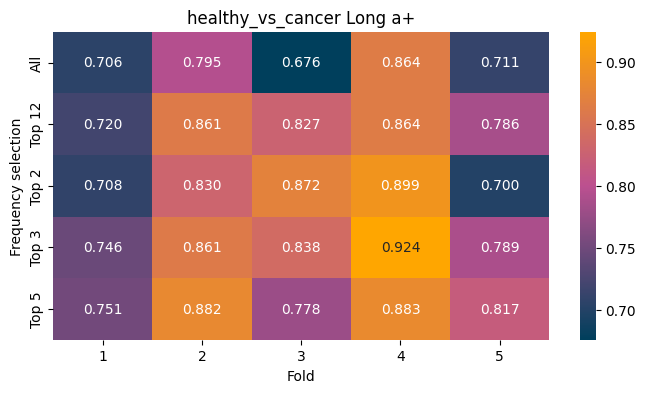

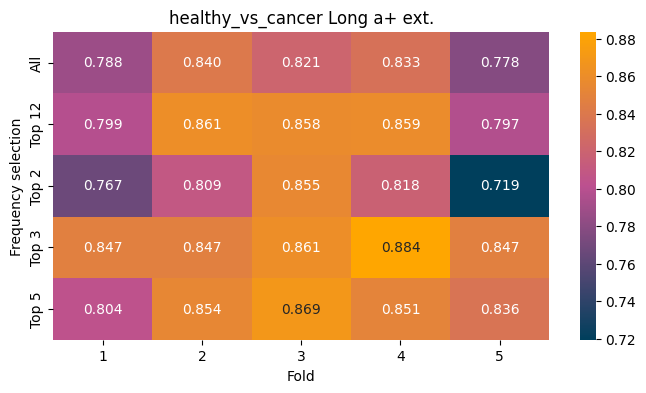

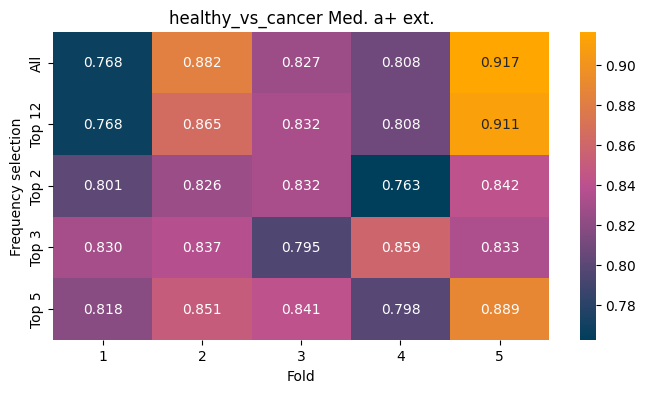

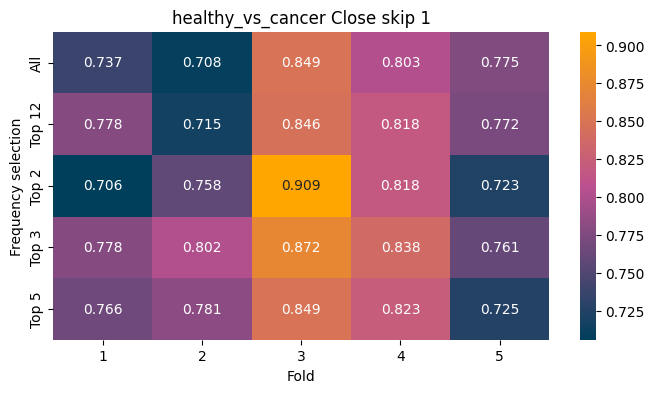

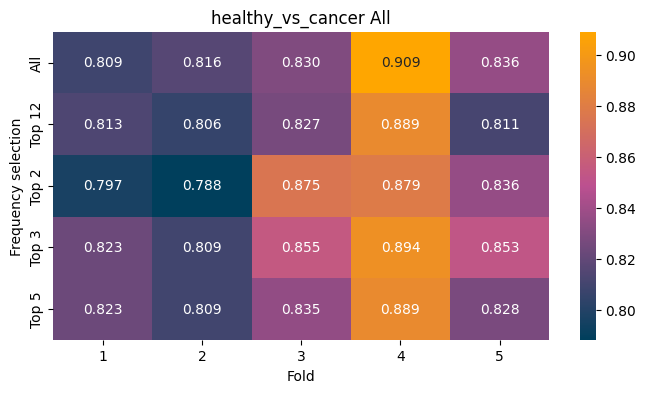

In [15]:
for mask_value in Mask_sel.keys():
    df_masked = df[df["Mask"] == mask_value]
    heatmap_data = df_masked.pivot(index="Fsel", columns="Fold", values="ROC_AUC_svm")

    plt.figure(figsize=(8, 4))
    sns.heatmap(heatmap_data, annot=True, cmap=cmap_gradient, fmt=".3f")
    plt.title(f"{class_task} {mask_value}")
    plt.ylabel("Frequency selection")
    plt.xlabel("Fold")
    plt.show()

In [22]:
Mask_sel

{'Long a+': 'vv_long_across',
 'Long a+ ext.': 'vv_long_across_extended',
 'Med. a+ ext.': 'vv_medium_across_extended',
 'Close skip 1': 'vv_distance_close_skip_1',
 'All': 'all'}

In [ ]:
for mask_value in Mask_sel.keys():
    df_masked = df[df["Mask"] == mask_value]
    heatmap_data = df_masked.pivot(index="Fsel", columns="Fold", values="ROC_AUC_svm")

    plt.figure(figsize=(8, 4))
    sns.heatmap(heatmap_data, annot=True, cmap=cmap_gradient, fmt=".3f")
    plt.title(f"{class_task} {mask_value}")
    plt.ylabel("Frequency selection")
    plt.xlabel("Fold")
    plt.show()

In [16]:
df.head()

,Fold,Num params.,Mask,Fsel,ROC_AUC_svm
0,1,32,Long a+,Top 2,0.708134
1,1,48,Long a+,Top 3,0.746411
2,1,80,Long a+,Top 5,0.751196
3,1,192,Long a+,Top 12,0.720096
4,1,496,Long a+,All,0.705742


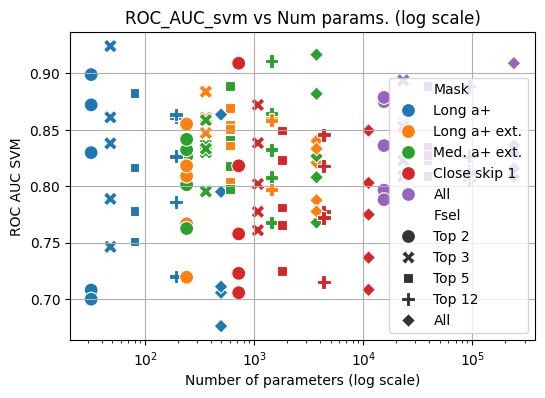

In [17]:
plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=df, x="Num params.", y="ROC_AUC_svm", hue="Mask", style="Fsel", s=100
)
plt.xscale("log")
plt.title("ROC_AUC_svm vs Num params. (log scale)")
plt.xlabel("Number of parameters (log scale)")
plt.ylabel("ROC AUC SVM")
plt.legend()
plt.grid(True)
plt.show()

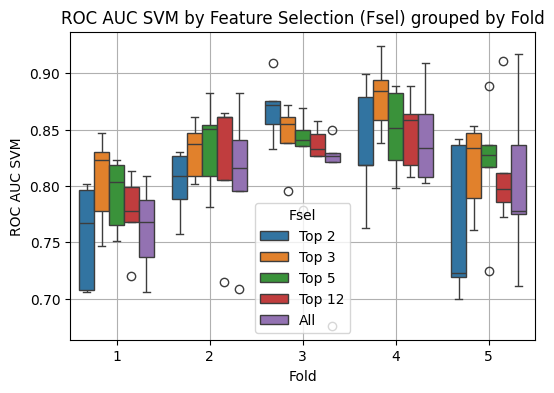

In [18]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Fold", y="ROC_AUC_svm", hue="Fsel")
plt.title("ROC AUC SVM by Feature Selection (Fsel) grouped by Fold")
plt.xlabel("Fold")
plt.ylabel("ROC AUC SVM")
plt.grid(True)
plt.show()

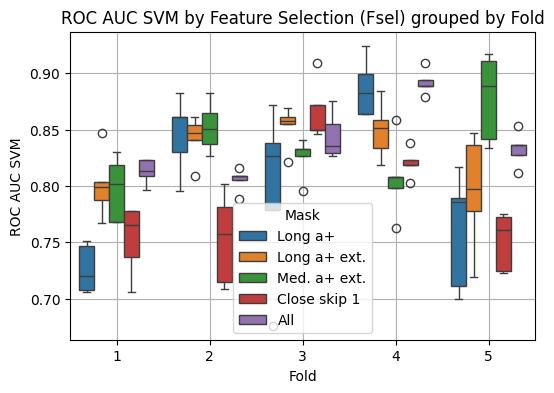

In [19]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Fold", y="ROC_AUC_svm", hue="Mask")
plt.title("ROC AUC SVM by Feature Selection (Fsel) grouped by Fold")
plt.xlabel("Fold")
plt.ylabel("ROC AUC SVM")
plt.grid(True)
plt.show()

In [20]:
print(df.groupby("Mask")["ROC_AUC_svm"].mean())
print(df.groupby("Fsel")["ROC_AUC_svm"].mean())
print(df.groupby("Fold")["ROC_AUC_svm"].mean())

Mask
All             0.837498
Close skip 1    0.788447
Long a+         0.803523
Long a+ ext.    0.828117
Med. a+ ext.    0.832037
Name: ROC_AUC_svm, dtype: float64
Fsel
All       0.803407
Top 12    0.819616
Top 2     0.805226
Top 3     0.835364
Top 5     0.826009
Name: ROC_AUC_svm, dtype: float64
Fold
1    0.777967
2    0.819757
3    0.837244
4    0.850960
5    0.803694
Name: ROC_AUC_svm, dtype: float64


In [21]:
df

,Fold,Num params.,Mask,Fsel,ROC_AUC_svm
0,1,32,Long a+,Top 2,0.708134
1,1,48,Long a+,Top 3,0.746411
2,1,80,Long a+,Top 5,0.751196
3,1,192,Long a+,Top 12,0.720096
4,1,496,Long a+,All,0.705742
...,...,...,...,...,...
120,5,15456,All,Top 2,0.836111
121,5,23184,All,Top 3,0.852778
122,5,38640,All,Top 5,0.827778
123,5,92736,All,Top 12,0.811111
